# 01 — Exploratory Data Analysis

This notebook explores the **Goodbooks-10k** dataset before building any model.
The goal is to understand how ratings are distributed across users and books,
and what the Goodreads tags look like, because these properties drive the
modelling choices made in the next notebooks.

**Files used** (downloaded with `download_data.sh` into `data/`):

| File | Content |
| --- | --- |
| `books.csv` | metadata for 10,000 books (title, authors, average rating, number of ratings…) |
| `ratings.csv` | ~6 million ratings (1–5 stars) given by 53,424 users |
| `book_tags.csv` | how many times each tag was applied to each book |
| `tags.csv` | tag id → tag name |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
})
COLOR = "#3b6fb6"

DATA = "../data"

## 1. Loading the data

In [2]:
books = pd.read_csv(f"{DATA}/books.csv")
ratings = pd.read_csv(f"{DATA}/ratings.csv")
tags = pd.read_csv(f"{DATA}/tags.csv")
book_tags = pd.read_csv(f"{DATA}/book_tags.csv")

print("books:    ", books.shape)
print("ratings:  ", ratings.shape)
print("book_tags:", book_tags.shape)
books[["book_id", "title", "authors", "average_rating", "ratings_count"]].head()

books:     (10000, 23)
ratings:   (5976479, 3)
book_tags: (999912, 3)


,book_id,title,authors,average_rating,ratings_count
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4.34,4780653
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4.44,4602479
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3.57,3866839
3,4,To Kill a Mockingbird,Harper Lee,4.25,3198671
4,5,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664


## 2. How sparse is the rating matrix?

A recommender works on a *user × book* matrix. Most users have read only a tiny
fraction of the catalogue, so most cells of this matrix are empty.

In [3]:
n_users = ratings["user_id"].nunique()
n_books = ratings["book_id"].nunique()
density = len(ratings) / (n_users * n_books)

print(f"Users:   {n_users:,}")
print(f"Books:   {n_books:,}")
print(f"Ratings: {len(ratings):,}")
print(f"Density of the user × book matrix: {density:.2%}")
print(f"Duplicate (user, book) pairs: {ratings.duplicated(['user_id', 'book_id']).sum()}")

Users:   53,424
Books:   10,000
Ratings: 5,976,479
Density of the user × book matrix: 1.12%


Duplicate (user, book) pairs: 0


Only about **1 %** of the user × book matrix is filled. This sparsity is the
central difficulty of collaborative filtering, and one reason to start with
models that rely on book metadata (tags, authors) instead.

## 3. Distribution of ratings

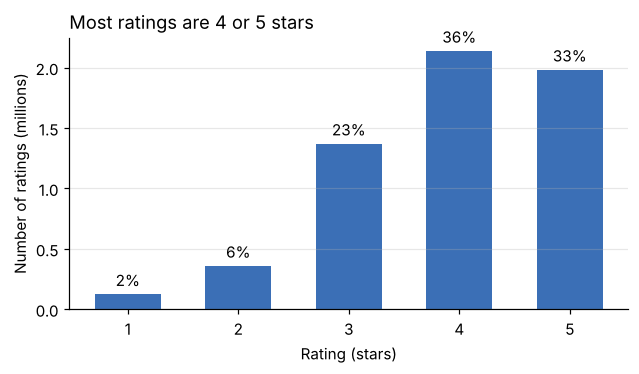

Mean rating: 3.92


In [4]:
counts = ratings["rating"].value_counts().sort_index()
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index.astype(str), counts.values / 1e6, color=COLOR, width=0.6)
ax.bar_label(bars, labels=[f"{s:.0%}" for s in shares], padding=3)
ax.set_title("Most ratings are 4 or 5 stars")
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of ratings (millions)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig("../figures/rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean rating: {ratings['rating'].mean():.2f}")

Ratings are strongly skewed towards the top: **69 %** of ratings are 4 or 5
stars, and the mean is 3.92. Users mostly rate books they chose to read and
liked, so a low rating is rare and therefore informative.

## 4. Activity per user and per book

In [5]:
per_user = ratings.groupby("user_id").size()
per_book = ratings.groupby("book_id").size()

pd.DataFrame({"ratings per user": per_user.describe(),
              "ratings per book": per_book.describe()}).round(1)

,ratings per user,ratings per book
count,53424.0,10000.0
mean,111.9,597.6
std,26.1,1267.3
min,19.0,8.0
25%,96.0,155.0
50%,111.0,248.0
75%,128.0,503.0
max,200.0,22806.0


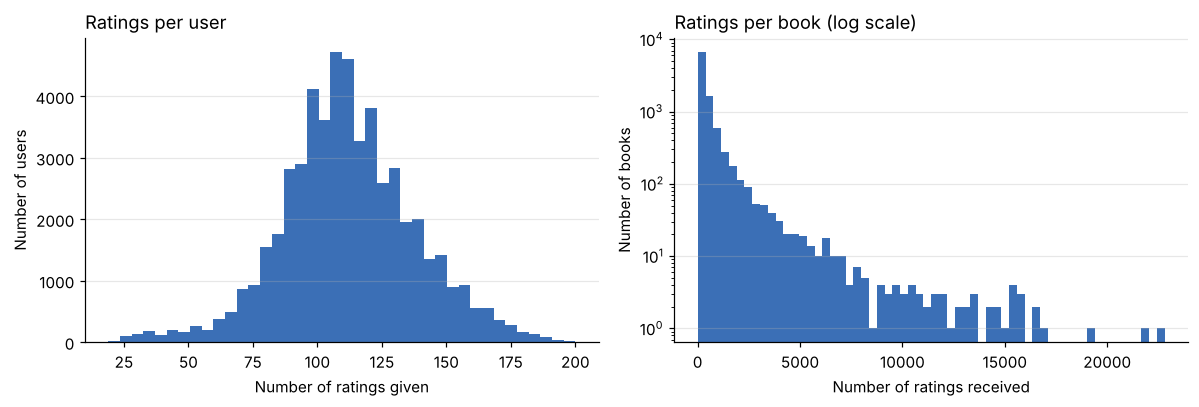

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(per_user, bins=40, color=COLOR)
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings given")
axes[0].set_ylabel("Number of users")

axes[1].hist(per_book, bins=60, color=COLOR)
axes[1].set_yscale("log")
axes[1].set_title("Ratings per book (log scale)")
axes[1].set_xlabel("Number of ratings received")
axes[1].set_ylabel("Number of books")

for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [7]:
top_share = per_book.sort_values(ascending=False).head(1000).sum() / len(ratings)
print(f"Share of all ratings received by the 10% most-rated books: {top_share:.0%}")

Share of all ratings received by the 10% most-rated books: 53%


- **Users** are fairly homogeneous: every user has between 19 and 200 ratings,
  with a median of 111. The dataset was built from active users only.
- **Books** follow a long-tail distribution: the median book has 248 ratings,
  but the most popular one has 22,806. The 10 % most-rated books receive more
  than half of all ratings.

This popularity bias matters: a naive model will keep recommending the same
bestsellers. The popularity baseline in notebook 02 makes this visible.

## 5. What do the Goodreads tags look like?

Tags are free text added by users. They are the main input of the
content-based model (notebook 02) and of the clustering (notebook 03).

In [8]:
bt = book_tags.merge(tags, on="tag_id")
tag_totals = bt.groupby("tag_name")["count"].sum().sort_values(ascending=False)
tag_totals.head(15)

tag_name
to-read               140718761
currently-reading       7507958
favorites               4503173
fiction                 3688819
fantasy                 3548157
young-adult             1848306
classics                1756920
books-i-own             1317235
romance                 1231926
owned                   1224279
ya                       898334
mystery                  872282
non-fiction              857901
historical-fiction       815421
series                   782637
Name: count, dtype: int64

The most frequent tags (`to-read`, `currently-reading`, `favorites`,
`books-i-own`…) describe the **user's shelf**, not the book's content.
They have to be removed before using tags as features. Once they are filtered
out, genres appear:

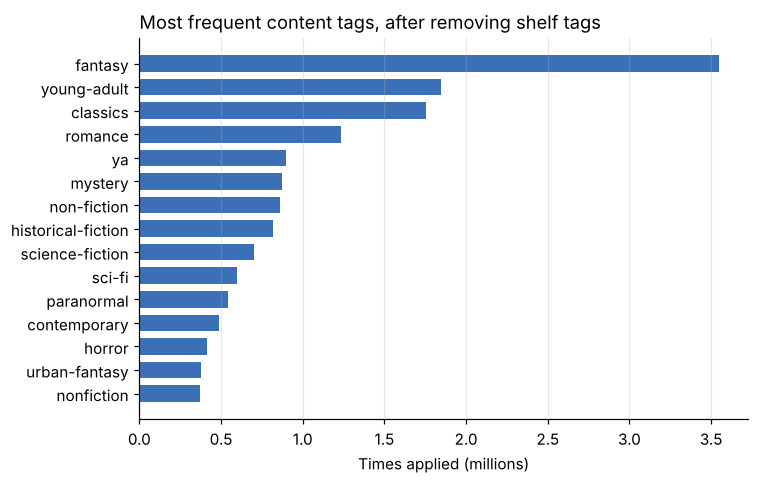

In [9]:
SHELF_PATTERN = r"read|own|favou?rite|kindle|library|ebook|audio|default|book-club|series|\d{4}|^fiction$"
content_tags = tag_totals[~tag_totals.index.str.contains(SHELF_PATTERN)].head(15)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(content_tags.index[::-1], content_tags.values[::-1] / 1e6, color=COLOR, height=0.7)
ax.set_title("Most frequent content tags, after removing shelf tags")
ax.set_xlabel("Times applied (millions)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Genres now dominate the list. Note the **synonyms** (`young-adult` and `ya`,
`science-fiction` and `sci-fi`): they are different tags for the same idea.
Notebook 03 handles them with a dimensionality reduction (truncated SVD).

## Key takeaways

1. The rating matrix is **~99 % empty**, which favours content-based methods as a first step.
2. Ratings are **skewed towards 4–5 stars** (mean 3.92).
3. Book popularity is a **long tail**: the top 10 % of books receive more than half of the ratings.
4. Tags are informative about genres, but **shelf tags must be filtered out** first.